# 📘 10 — Matplotlib & Seaborn
*Part of the Full Stack Data Science & AI booklet. Run cells top to bottom (Shift + Enter). Install libraries first: `pip install -r ../requirements.txt`.*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os, sys, math, random, json, time, copy, warnings
from IPython.display import display
warnings.filterwarnings("ignore")

# 1️⃣1️⃣ Data Visualization — Matplotlib & Seaborn
- **Matplotlib** = the foundation (full control).
- **Seaborn** = built on Matplotlib, prettier statistical charts in one line.

**Which chart when?**
| Question | Chart |
|---|---|
| Trend over time | Line |
| Compare categories | Bar |
| Distribution of one variable | Histogram / KDE / Box |
| Relationship of two numbers | Scatter |
| Parts of a whole | Pie (few slices) |
| Correlations | Heatmap |
| Many relationships at once | Pairplot |
## 11.1 Matplotlib basics

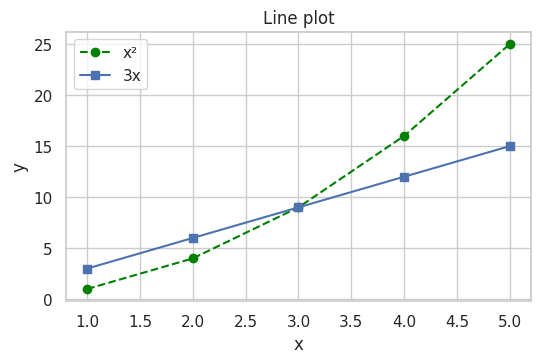

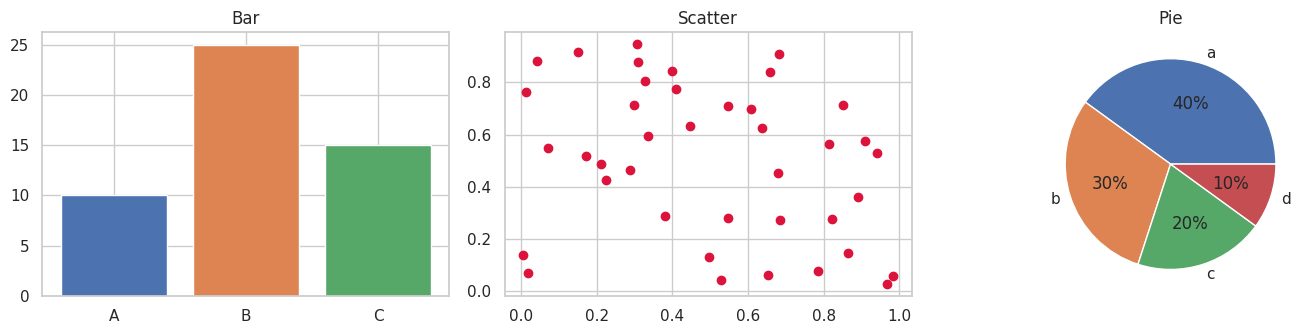

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd, numpy as np
sns.set_theme(style="whitegrid")

x = np.arange(1, 6); y = x ** 2
plt.figure(figsize=(6, 3.5))
plt.plot(x, y, marker="o", color="green", linestyle="--", label="x²")
plt.plot(x, x * 3, marker="s", label="3x")
plt.title("Line plot"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))            # subplots = many charts
axes[0].bar(["A", "B", "C"], [10, 25, 15], color=["#4c72b0", "#dd8452", "#55a868"]); axes[0].set_title("Bar")
axes[1].scatter(np.random.rand(40), np.random.rand(40), c="crimson"); axes[1].set_title("Scatter")
axes[2].pie([40, 30, 20, 10], labels=["a", "b", "c", "d"], autopct="%1.0f%%"); axes[2].set_title("Pie")
plt.tight_layout(); plt.show()
# plt.savefig("chart.png", dpi=200)   # save as image

#### 🔍 How Matplotlib charts are formed
- **Figure** = the whole canvas; **Axes** = one chart area inside it. `plt.subplots(1, 3)` makes 3 side-by-side axes.
- `plot(x, y)` draws a line (`marker`, `color`, `linestyle`, `label` style it); `bar(categories, heights)`; `scatter(x, y)`; `pie(values, labels, autopct)`.
- Always add `title`, `xlabel`, `ylabel`, `legend` — **a chart without labels is useless to a manager**. `tight_layout()` fixes overlaps; `savefig` exports a PNG for slides.
#### 💼 Where it's used
Every report/dashboard. Choose the chart to match the question (trend → line, compare → bar, relationship → scatter, distribution → histogram).

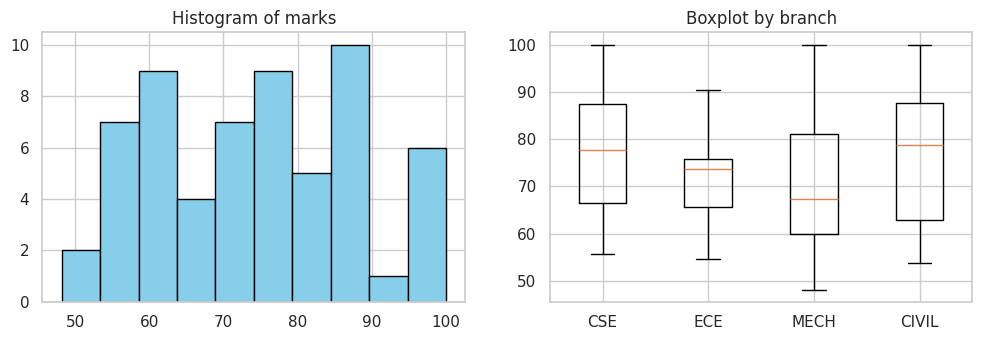

In [3]:
students = pd.read_csv("data/students.csv").fillna({"marks": 60})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(students.marks, bins=10, color="skyblue", edgecolor="black"); ax[0].set_title("Histogram of marks")
branches = ["CSE", "ECE", "MECH", "CIVIL"]
ax[1].boxplot([students[students.branch == b].marks for b in branches])
ax[1].set_xticks(range(1, 5), branches); ax[1].set_title("Boxplot by branch")   # tick labels set separately (works on all Matplotlib versions)
plt.show()

#### 🔍 How it works
- **Histogram:** cuts marks into 10 bins and counts how many students are in each; bars show the **shape** of the data (centre, spread, skew).
- **Box plot:** one box per branch → compare medians and spread side by side; dots outside the whiskers are outliers.

## 11.2 Seaborn — statistical charts

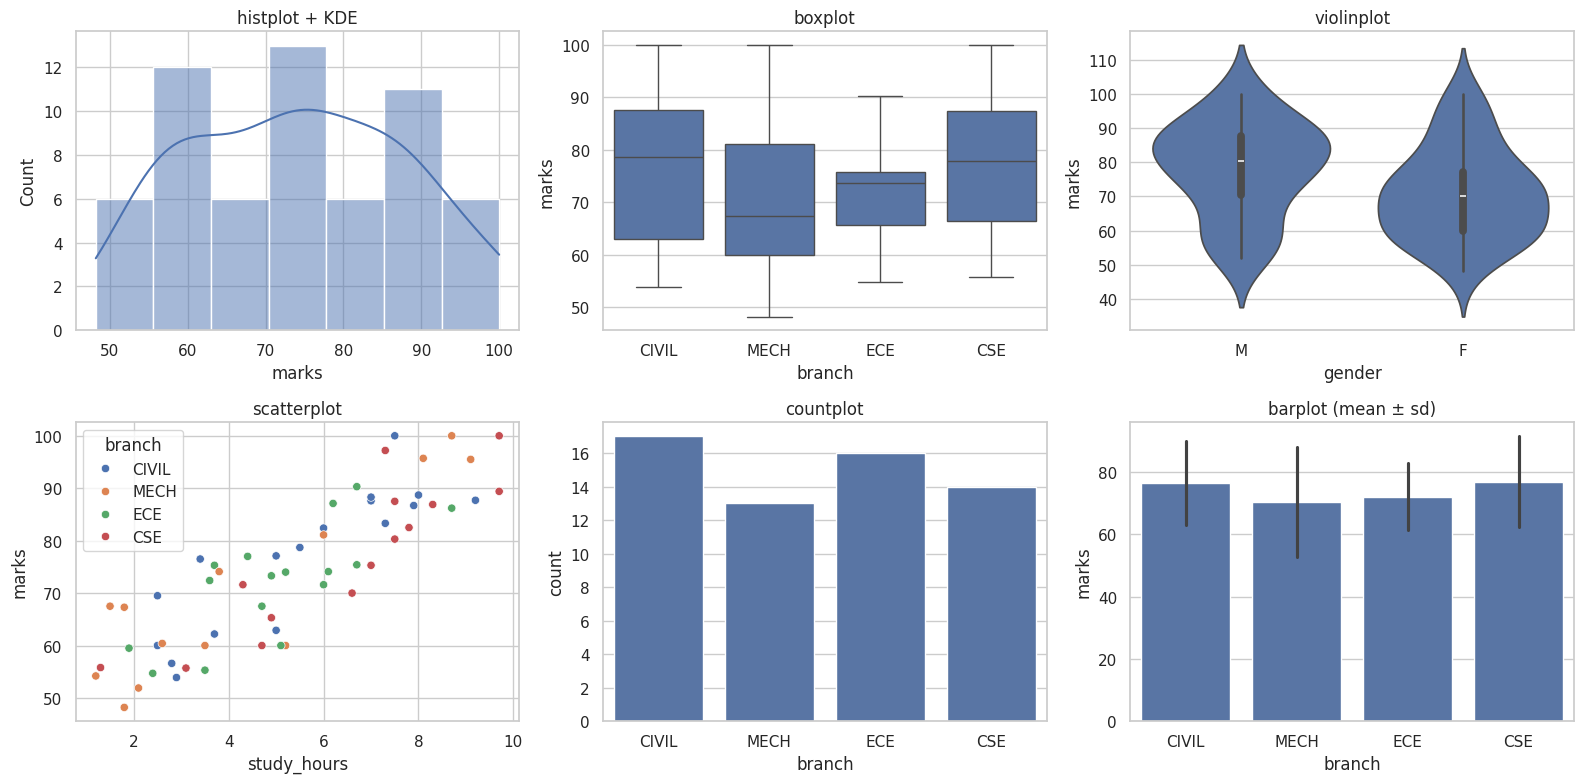

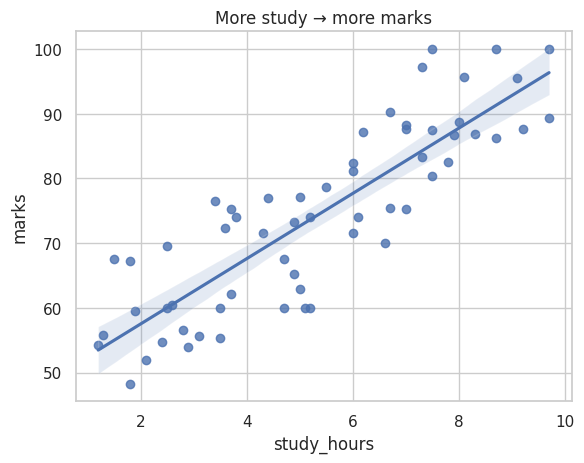

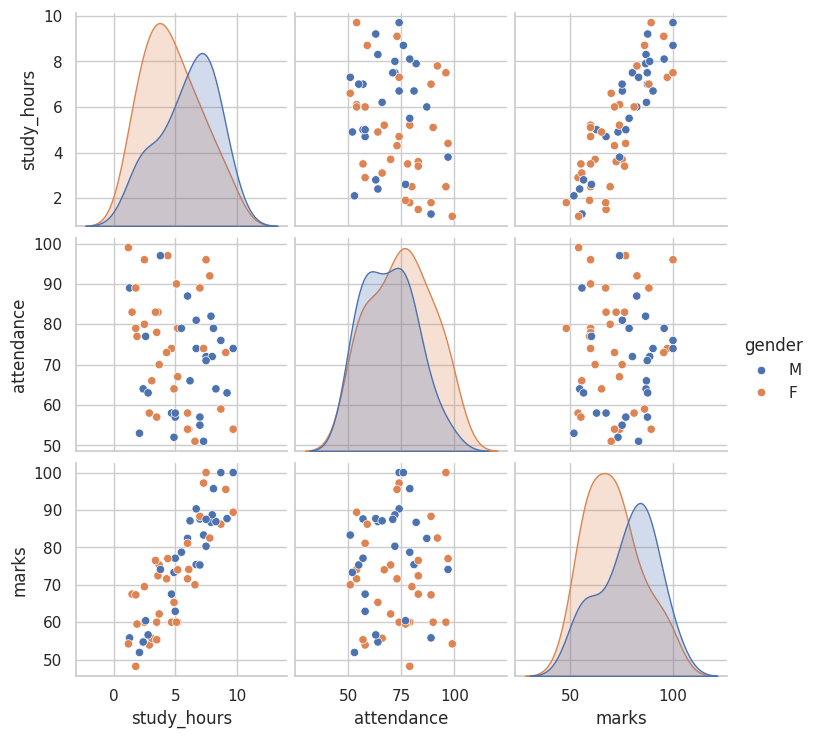

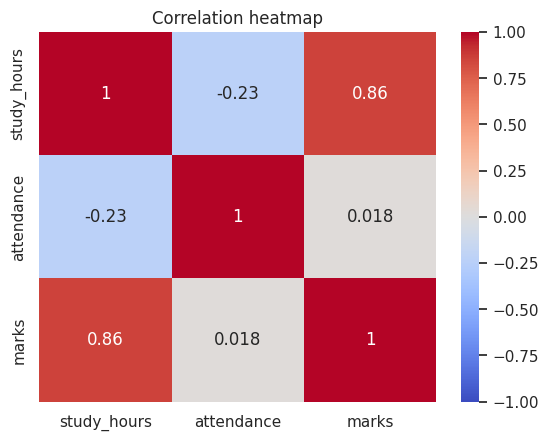

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(students.marks, kde=True, ax=ax[0, 0]).set_title("histplot + KDE")
sns.boxplot(data=students, x="branch", y="marks", ax=ax[0, 1]).set_title("boxplot")
sns.violinplot(data=students, x="gender", y="marks", ax=ax[0, 2]).set_title("violinplot")
sns.scatterplot(data=students, x="study_hours", y="marks", hue="branch", ax=ax[1, 0]).set_title("scatterplot")
sns.countplot(data=students, x="branch", ax=ax[1, 1]).set_title("countplot")
sns.barplot(data=students, x="branch", y="marks", errorbar="sd", ax=ax[1, 2]).set_title("barplot (mean ± sd)")
plt.tight_layout(); plt.show()

sns.regplot(data=students, x="study_hours", y="marks")                 # scatter + regression line
plt.title("More study → more marks"); plt.show()
sns.pairplot(students[["study_hours", "attendance", "marks", "gender"]], hue="gender"); plt.show()
sns.heatmap(students[["study_hours", "attendance", "marks"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap"); plt.show()

#### 🔍 How each Seaborn chart above is formed
- `histplot(kde=True)` histogram + smooth curve; `boxplot` median/quartiles/outliers per group; `violinplot` box + density shape; `scatterplot(hue=...)` dots coloured by group; `countplot` counts rows per category; `barplot` shows the mean per category with an error bar.
- `regplot` adds the best-fit line; `pairplot` plots every column against every other; `heatmap(corr, annot=True)` colours the correlation table: **red = positive, blue = negative**, near ±1 = strong relation.
- `ax=ax[0, 1]` tells Seaborn *which panel* to draw on (that's how 6 charts share one figure).
#### 💼 Where it's used
**EDA reports** and stakeholder presentations; the correlation heatmap is how you decide which features to keep for a model.

## 11.3 🌊 Seaborn Bootcamp — 15 charts on the `tips` dataset
**Dataset:** each row = one restaurant bill: `total_bill`, `tip`, `sex`, `smoker`, `day`, `time`, `size` (party size).
**Why charts?** A manager reads a chart in 5 seconds; a table takes 5 minutes. As an analyst you build the chart, and **explain the insight** (you don't explain the code).

**How every Seaborn chart is formed (3 steps):** ① `data=` the DataFrame ② `x=`, `y=` the columns to place on the axes ③ `hue=` (colour split), `size=`, `style=` add extra columns as visual channels. Seaborn then groups/aggregates the data and draws it on a Matplotlib axes; `plt.title/show` finish it.

In [5]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
tips = pd.read_csv("data/tips_dataset.csv")
sns.set_theme(style="darkgrid")                 # one global look: background + grid
print(tips.shape); display(tips.head(3))
print(tips.dtypes.to_dict())
print("sex:", tips.sex.unique(), "| day:", tips.day.unique())

(244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3


{'total_bill': dtype('float64'), 'tip': dtype('float64'), 'sex': <StringDtype(storage='python', na_value=nan)>, 'smoker': <StringDtype(storage='python', na_value=nan)>, 'day': <StringDtype(storage='python', na_value=nan)>, 'time': <StringDtype(storage='python', na_value=nan)>, 'size': dtype('int64')}
sex: <StringArray>
['Female', 'Male']
Length: 2, dtype: str | day: <StringArray>
['Sun', 'Sat', 'Thur', 'Fri']
Length: 4, dtype: str


#### 🔍 How it works
- `warnings.filterwarnings("ignore")` hides non-critical library warnings (use carefully; never hide errors).
- `sns.set_theme(style="darkgrid")` sets a global style so all later charts look consistent.
- `.shape` = (rows, columns); `.dtypes` shows which columns are numbers vs text (text columns become *categories* on charts).

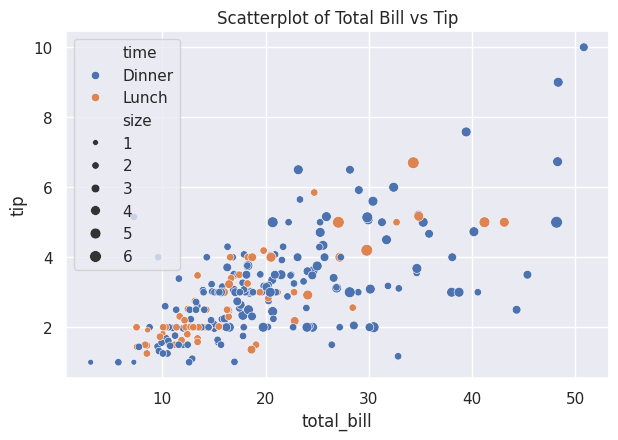

In [6]:
# 1) SCATTER — relationship between two numbers
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", size="size", palette="deep")
plt.title("Scatterplot of Total Bill vs Tip"); plt.show()

**① Scatter** · *How it's formed:* every row becomes one dot at (total_bill, tip); `hue` colours dots by time, `size` scales dot area by party size. · *Why:* shows **correlation** (dots rising to the right = bigger bills → bigger tips) and **outliers**. · *Job use:* price vs demand, ad spend vs sales, feature vs target before modelling.

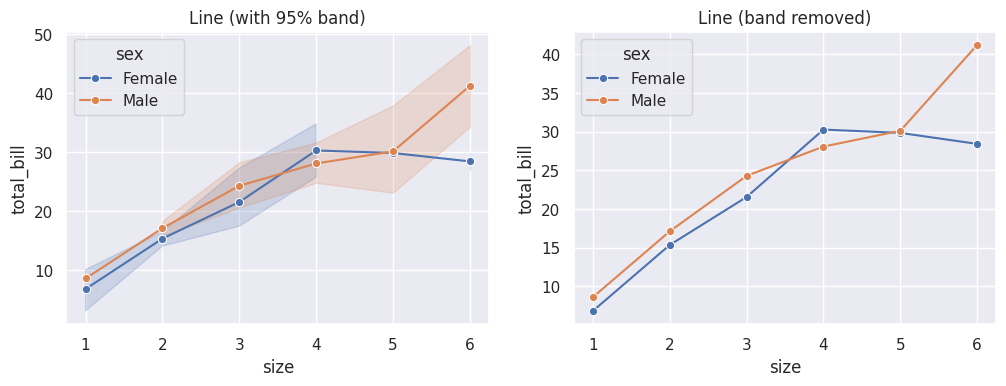

In [7]:
# 2) LINE — trend of an average (Seaborn averages y for each x and draws a confidence band)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.lineplot(data=tips, x="size", y="total_bill", hue="sex", marker="o", ax=ax[0]); ax[0].set_title("Line (with 95% band)")
sns.lineplot(data=tips, x="size", y="total_bill", hue="sex", errorbar=None, marker="o", ax=ax[1]); ax[1].set_title("Line (band removed)")
plt.show()

**② Line** · *Formed:* for each `size`, Seaborn takes the **mean** of `total_bill` per `sex`, joins those means with a line, and shades the **95% confidence interval** (turn off with `errorbar=None`). · *Why:* shows trend and uncertainty. · *Job use:* sales over months, daily active users, server load.

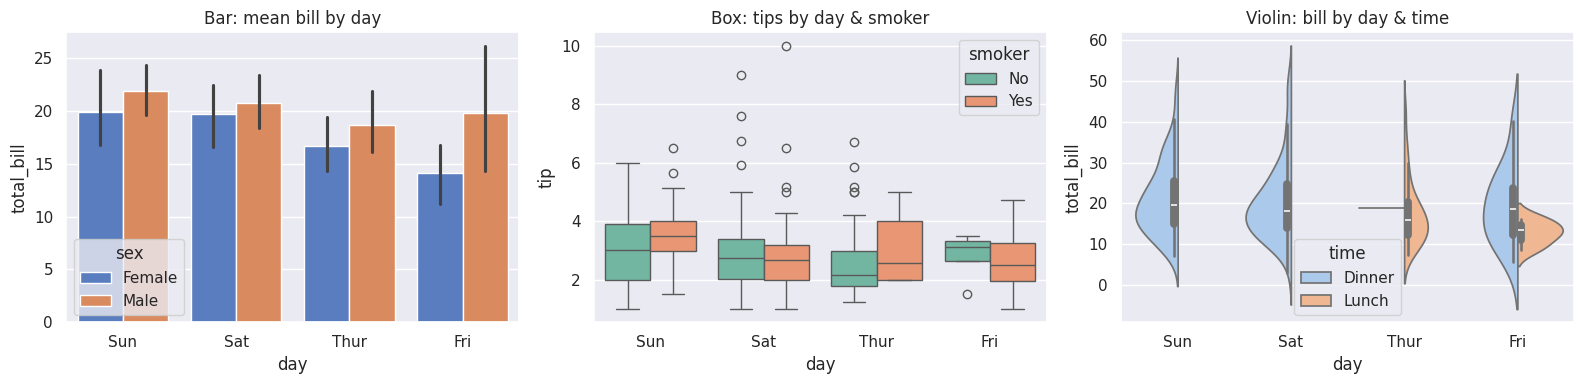

In [8]:
# 3) BAR (mean of a number per category), 4) BOX (distribution + outliers), 5) VIOLIN (distribution shape)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=tips, x="day", y="total_bill", hue="sex", palette="muted", ax=ax[0]); ax[0].set_title("Bar: mean bill by day")
sns.boxplot(data=tips, x="day", y="tip", hue="smoker", palette="Set2", ax=ax[1]); ax[1].set_title("Box: tips by day & smoker")
sns.violinplot(data=tips, x="day", y="total_bill", hue="time", split=True, palette="pastel", ax=ax[2]); ax[2].set_title("Violin: bill by day & time")
plt.tight_layout(); plt.show()

**③ Bar** · *Formed:* height = **mean** of y per category (error bar = uncertainty). · *Job use:* compare revenue per region/product.
**④ Box** · *Formed:* box = middle 50% of values (Q1→Q3), line inside = **median**, whiskers = 1.5×IQR, dots beyond = **outliers**. · *Why:* compare spread and spot outliers across groups. · *Job use:* delivery times by city, salary bands, fraud/anomaly checks.
**⑤ Violin** · *Formed:* a box plot + a mirrored **KDE** (smooth density curve); `split=True` puts two hue groups on the two halves. · *Why:* shows *shape* (one hump or two?), which a box hides.

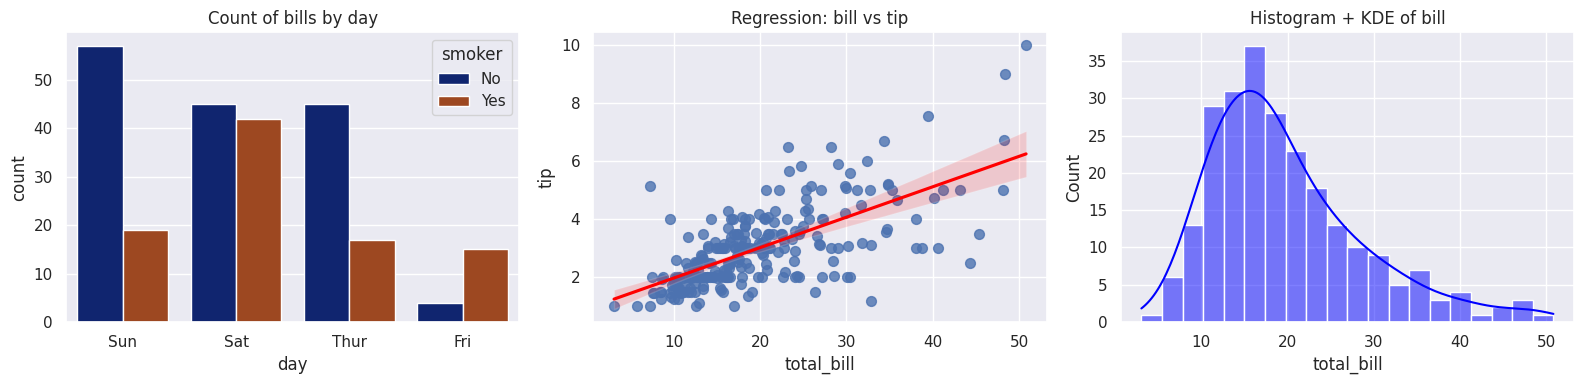

In [9]:
# 6) COUNT (how many rows per category), 7) REGRESSION line, 8) HISTOGRAM + KDE
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=tips, x="day", hue="smoker", palette="dark", ax=ax[0]); ax[0].set_title("Count of bills by day")
sns.regplot(data=tips, x="total_bill", y="tip", scatter_kws={"s": 50}, line_kws={"color": "red"}, ax=ax[1]); ax[1].set_title("Regression: bill vs tip")
sns.histplot(data=tips, x="total_bill", bins=20, kde=True, color="blue", ax=ax[2]); ax[2].set_title("Histogram + KDE of bill")
plt.tight_layout(); plt.show()

**⑥ Count** · *Formed:* Seaborn **counts rows** per category (no y needed). · *Job use:* orders per weekday, class balance before ML (is 95% of data one class?).
**⑦ Regression plot** · *Formed:* scatter + the **best-fit straight line** (least squares) + shaded confidence band. · *Why:* a quick visual of linear regression; the red line is what a simple model would predict.
**⑧ Histogram + KDE** · *Formed:* the x-range is cut into `bins=20` buckets; bar height = how many rows fall in each; **KDE** draws a smooth curve over it. · *Why:* shows distribution shape (symmetric? skewed? outliers?). · *Job use:* checking if data is normal before using a t-test or linear model.

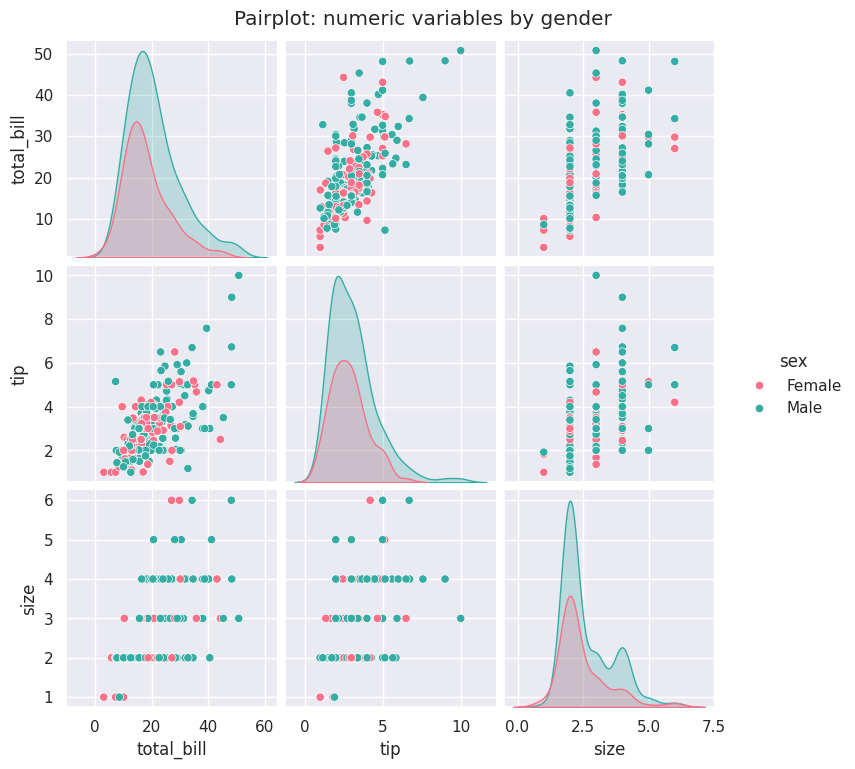

In [10]:
# 9) PAIRPLOT — every numeric column vs every other (a matrix of scatter/hist plots)
sns.pairplot(tips, hue="sex", vars=["total_bill", "tip", "size"], palette="husl")
plt.suptitle("Pairplot: numeric variables by gender", y=1.02); plt.show()

**⑨ Pairplot** · *Formed:* a grid; off-diagonal cells are scatter plots of column pairs, the diagonal shows each column's distribution. · *Why:* the fastest first look at **all relationships at once**. · *Job use:* the first EDA step on any new dataset; choosing features for a model.

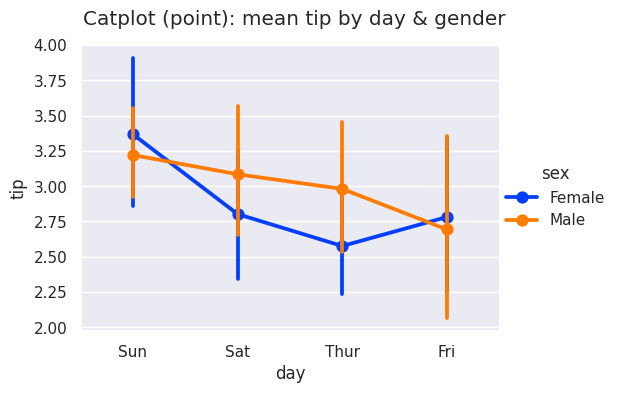

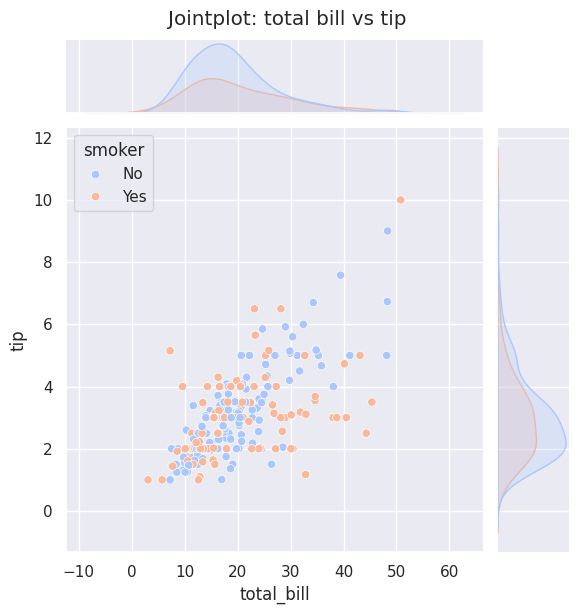

In [11]:
# 10) CATPLOT (kind="point"), 11) JOINTPLOT (scatter + marginal histograms)
g = sns.catplot(data=tips, x="day", y="tip", hue="sex", kind="point", palette="bright", height=3.8, aspect=1.4)
g.fig.suptitle("Catplot (point): mean tip by day & gender", y=1.03); plt.show()
sns.jointplot(data=tips, x="total_bill", y="tip", kind="scatter", hue="smoker", palette="coolwarm")
plt.suptitle("Jointplot: total bill vs tip", y=1.02); plt.show()

**⑩ Catplot** · one function for many categorical charts (`kind="point"/"bar"/"box"/"violin"/"strip"`); `point` plots the **mean + CI** per category and connects them to show *change across categories*. · *Job use:* comparing groups (A/B test arms, regions).
**⑪ Jointplot** · *Formed:* centre = scatter of x vs y, top/right = histograms of each variable alone. · *Why:* relationship **and** individual distributions in one view.

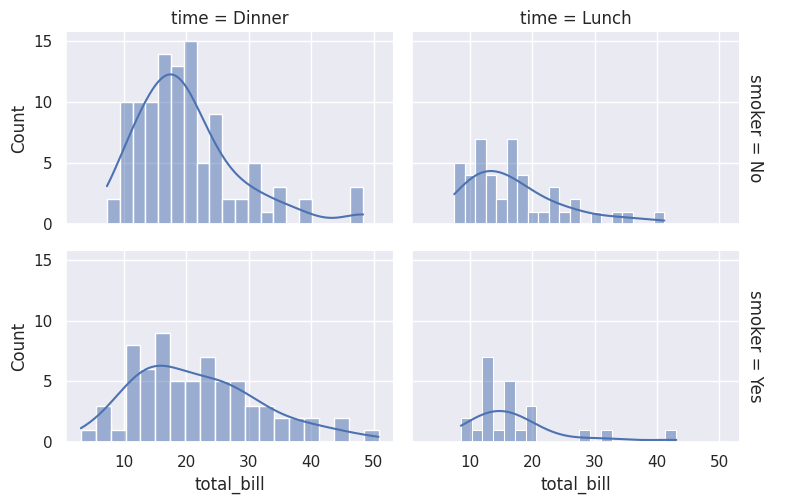

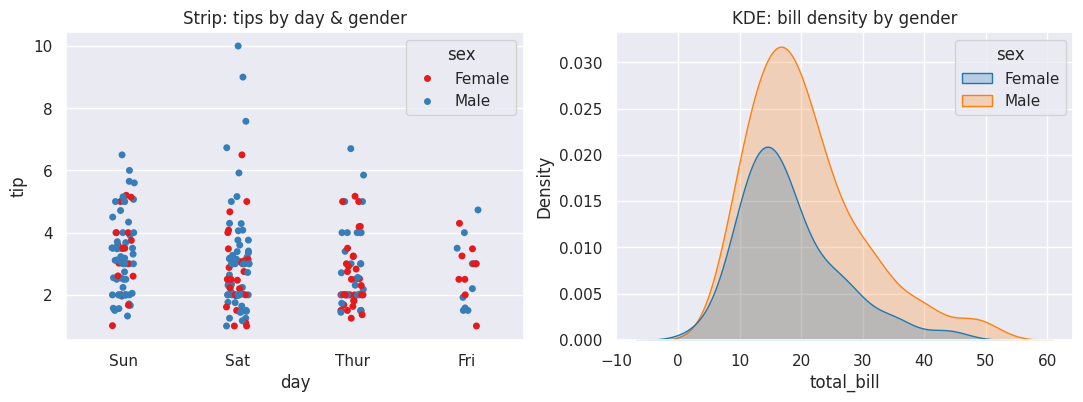

In [12]:
# 12) FACETGRID — the same chart repeated for every combination of two categories
g = sns.FacetGrid(tips, col="time", row="smoker", margin_titles=True, height=2.6, aspect=1.5)
g.map(sns.histplot, "total_bill", bins=20, kde=True).add_legend()
plt.show()

# 13) STRIP (every individual point, jittered), 14) KDE (smooth density, filled)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.stripplot(data=tips, x="day", y="tip", hue="sex", jitter=True, palette="Set1", ax=ax[0]); ax[0].set_title("Strip: tips by day & gender")
sns.kdeplot(data=tips, x="total_bill", hue="sex", fill=True, palette="tab10", ax=ax[1]); ax[1].set_title("KDE: bill density by gender")
plt.show()

**⑫ FacetGrid** · *Formed:* Seaborn splits the data by `col` and `row` values and draws the **same histogram** in each small panel (`.map`). · *Why:* compare many sub-groups without overlapping lines. · *Job use:* one chart per region/product line.
**⑬ Strip** · *Formed:* each row is one dot; `jitter` shifts dots sideways so they don't overlap. · *Why:* shows **raw points + sample size** (box plots hide those).
**⑭ KDE** · *Formed:* each data point contributes a small bell curve; all are added up to a smooth density; `fill=True` shades it. Area under the curve = 1. · *Why:* smoother than a histogram for comparing groups.

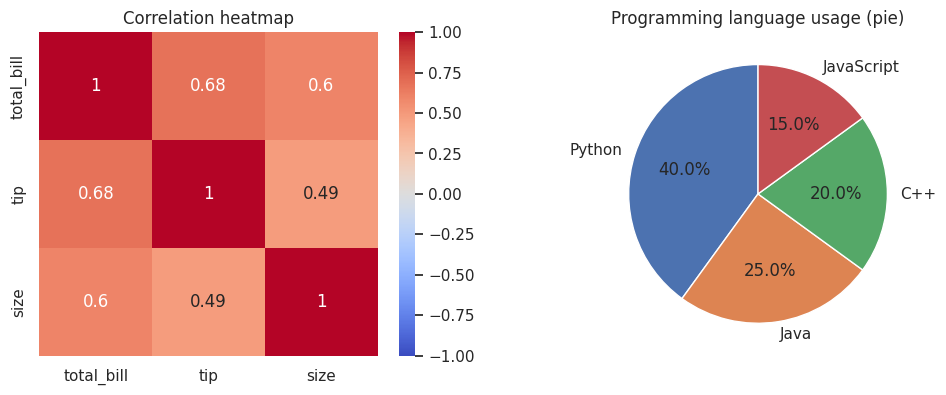

Analyst note: dinner & weekend bills are larger; tips rise with bill size (r = 0.68 )


In [13]:
# 15) HEATMAP of correlations + matplotlib PIE chart (parts of a whole)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(tips[["total_bill", "tip", "size"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title("Correlation heatmap")
labels, values = ["Python", "Java", "C++", "JavaScript"], [40, 25, 20, 15]
ax[1].pie(values, labels=labels, autopct="%1.1f%%", startangle=90); ax[1].set_title("Programming language usage (pie)")
plt.show()
print("Analyst note: dinner & weekend bills are larger; tips rise with bill size (r =", round(tips.total_bill.corr(tips.tip), 2), ")")

**⑮ Heatmap** · *Formed:* `.corr()` builds a table of correlations (−1 to +1); each cell is **coloured by its value**, `annot=True` prints the number. · *Job use:* spot redundant features (two columns with r ≈ 1) before ML.
**Pie** · *Formed:* each value ÷ total × 360° = slice angle; `autopct` writes the percentage. · *Use only for 3–5 parts of one whole*; bars are clearer for comparisons.

> 🎯 **Analyst mindset:** build the chart → state the insight in one sentence ("weekend dinner bills are the largest") → recommend an action. Managers need the *story*, not the code.

## 🚀 Mini Project 8: Sales Dashboard

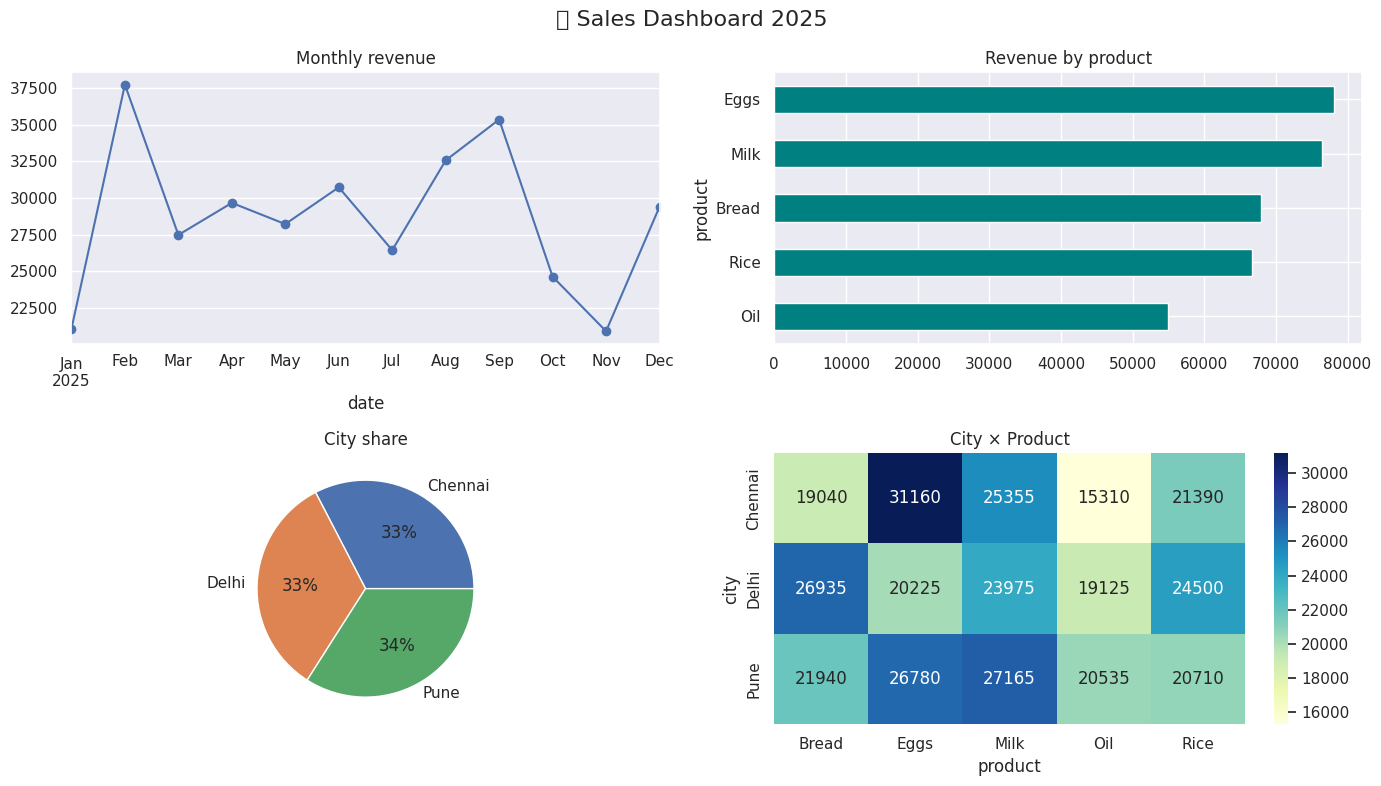

In [14]:
sales = pd.read_csv("data/sales.csv", parse_dates=["date"])
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
sales.set_index("date").resample("ME").revenue.sum().plot(ax=ax[0, 0], marker="o", title="Monthly revenue")
sales.groupby("product").revenue.sum().sort_values().plot.barh(ax=ax[0, 1], title="Revenue by product", color="teal")
sales.groupby("city").revenue.sum().plot.pie(ax=ax[1, 0], autopct="%1.0f%%", title="City share")
sales.pivot_table(index="city", columns="product", values="revenue", aggfunc="sum").pipe(sns.heatmap, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax[1, 1])
ax[1, 1].set_title("City × Product")
fig.suptitle("📊 Sales Dashboard 2025", fontsize=16); plt.tight_layout(); plt.show()

#### 🔍 How the dashboard is built
- `.resample("ME").revenue.sum().plot(...)` → total revenue per month drawn as a line; `.sort_values().plot.barh` → sorted horizontal bars (ranking is easier to read when sorted); `.plot.pie(autopct=...)` → share of each city; `pivot_table(...).pipe(sns.heatmap, ...)` → city × product grid, darker colour = more revenue.
- `suptitle` is the title for the whole figure.
#### 💼 Where it's used
Business dashboards (Power BI / Tableau / Streamlit) show exactly these 4 views: **trend, ranking, share, and comparison grid**.

### 🧪 Practice (Section 11)
1. Plot marks vs attendance with a regression line. 2. Draw a boxplot to spot outliers in `fare` (passengers.csv). 3. Make a heatmap of the correlation matrix of houses.csv. 4. Create a 2×2 dashboard from any CSV.